# Fashion-MNIST Image Classification Using CNN

## Project Objective

The objective of this project is to develop a Convolutional Neural Network (CNN) capable of classifying grayscale clothing images into 10 different categories using the Fashion-MNIST dataset.

The project explores image preprocessing, convolutional feature extraction, model development, training and performance evaluation.

## Problem Statement

Image classification is an important task in computer vision. This project investigates how CNNs can automatically learn visual features from clothing images and use them to distinguish between different categories.

## Dataset

The Fashion-MNIST dataset consists of 70,000 grayscale images, each measuring 28 × 28 pixels, divided into 60,000 training images and 10,000 testing images.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense, Dropout
)
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)

# Load dataset
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

TensorFlow version: 2.21.0
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


## 2. Data Exploration and Visualisation

Before training the model, we explore the Fashion-MNIST dataset to understand the structure and appearance of the input images.

Each image is a 28 × 28 grayscale representation of a clothing item. The following visualisation displays 10 sample training images along with their corresponding class labels.

This step helps us understand the different clothing categories that the CNN model will learn to recognise.


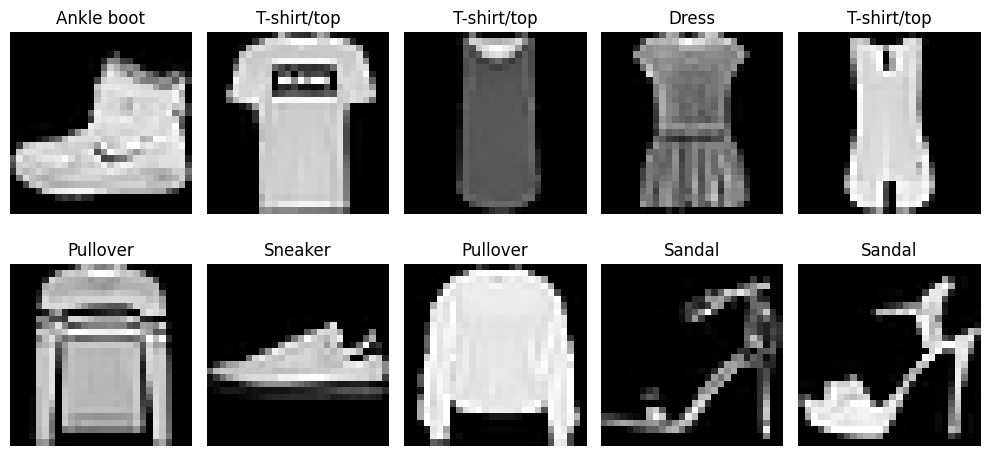

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 3. Data Preprocessing

Before feeding the images into the Convolutional Neural Network, the dataset undergoes preprocessing to ensure compatibility with the model.

### 3.1 Image Normalisation

The original pixel values range from 0 to 255. These values are converted into floating-point numbers and normalised to the range of 0 to 1 by dividing each pixel value by 255.

### 3.2 Adding the Channel Dimension

The original Fashion-MNIST images have dimensions of 28 × 28 pixels. Since the CNN uses a Conv2D layer, the images must follow the format (samples, height, width, channels).

An additional channel dimension is introduced using NumPy's `newaxis` operation. Since the images are grayscale, the channel dimension is 1.

The resulting training input shape is (60000, 28, 28, 1).

In [ ]:
# Normalize pixels from 0–255 to 0–1
x_train_cnn = x_train.astype("float32") / 255.0
x_test_cnn = x_test.astype("float32") / 255.0

# Add the grayscale channel dimension
x_train_cnn = x_train_cnn[..., np.newaxis]
x_test_cnn = x_test_cnn[..., np.newaxis]

print("CNN input shape:", x_train_cnn.shape)

CNN input shape: (60000, 28, 28, 1)


## 4. Build the CNN model

In [ ]:
cnn_model = Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## CNN Model Architecture

A Sequential Convolutional Neural Network (CNN) is constructed using TensorFlow and Keras to classify Fashion-MNIST images into 10 clothing categories.

### Architecture Components

**1. Input Layer**

Accepts grayscale images with dimensions of 28 × 28 pixels and one channel.

**2. First Convolutional Layer**

Uses 32 filters of size 3 × 3 with ReLU activation to extract basic visual features.

**3. First Max Pooling Layer**

Uses a 2 × 2 pooling window to reduce the spatial dimensions of the feature maps.

**4. Second Convolutional Layer**

Uses 64 filters of size 3 × 3 with ReLU activation to learn more complex visual patterns.

**5. Second Max Pooling Layer**

Further reduces the spatial dimensions of the extracted feature maps.

**6. Flatten Layer**

Converts the multidimensional feature maps into a one-dimensional vector of 1,600 values.

**7. Dense Layer**

Contains 128 neurons with ReLU activation to learn combinations of extracted features for classification.

**8. Dropout Layer**

Applies a dropout rate of 0.3 during training to help reduce overfitting.

**9. Output Layer**

Contains 10 neurons with Softmax activation, producing class probabilities for the 10 clothing categories.

### Model Compilation

The model is compiled using:

- Optimizer: Adam
- Loss Function: Sparse Categorical Crossentropy
- Evaluation Metric: Accuracy

The model summary reports 225,034 trainable parameters.

## 5. Model Training

After defining and compiling the CNN architecture, the model is trained using the preprocessed Fashion-MNIST training dataset.

The `fit()` method is used to train the network by learning patterns from the input images and their corresponding labels.

### Training Configuration

- **Epochs:** 5
- **Batch Size:** 128
- **Validation Split:** 10%
- **Optimizer:** Adam
- **Loss Function:** Sparse Categorical Crossentropy

### Training Process

During training, the model processes the training images in batches and updates its weights to minimise prediction errors.

A validation split of 10% is used to monitor model performance on data excluded from weight updates during training.

The training history is stored in `cnn_history`, allowing training and validation accuracy and loss to be visualised later.

In [ ]:
cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 96ms/step - accuracy: 0.7776 - loss: 0.6242 - val_accuracy: 0.8577 - val_loss: 0.3903
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 96ms/step - accuracy: 0.8589 - loss: 0.3913 - val_accuracy: 0.8798 - val_loss: 0.3280
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 97ms/step - accuracy: 0.8771 - loss: 0.3393 - val_accuracy: 0.8868 - val_loss: 0.3112
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 80s 93ms/step - accuracy: 0.8874 - loss: 0.3067 - val_accuracy: 0.8950 - val_loss: 0.2851
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 93ms/step - accuracy: 0.8958 - loss: 0.2850 - val_accuracy: 0.8900 - val_loss: 0.2923


## 6. Model Evaluation

After completing the training process, the CNN model is evaluated using the separate Fashion-MNIST testing dataset.

The `evaluate()` method measures the model's performance on previously unseen images.

### Evaluation Metrics

- **Test Loss:** Measures the prediction error on the testing dataset.
- **Test Accuracy:** Measures the proportion of correctly classified test images.

The testing dataset contains 10,000 images and is kept separate from the training process to assess the model's ability to generalise to unseen data.

The evaluation results provide an indication of how effectively the trained CNN performs the image classification task.

In [ ]:
test_loss, test_accuracy = cnn_model.evaluate(
    x_test_cnn, y_test, verbose=0
)

print(f"CNN Test Loss: {test_loss:.4f}")
print(f"CNN Test Accuracy: {test_accuracy:.4f}")
print(f"CNN Test Accuracy: {test_accuracy * 100:.2f}%")

CNN Test Loss: 0.3145
CNN Test Accuracy: 0.8853
CNN Test Accuracy: 88.53%


### Evaluation Results

The trained CNN model was evaluated using 10,000 unseen test images from the Fashion-MNIST dataset.

The model achieved the following results:

| Evaluation Metric | Result |
|---|---:|
| Test Accuracy | 88.53% |
| Test Loss | 0.3145 |

The test accuracy indicates that the model correctly classified approximately 88.53% of the testing images.

These results demonstrate the model's ability to learn useful visual features and generalise to previously unseen clothing images.

## 7. Training and Validation Performance Visualisation

To analyse the learning behaviour of the CNN model, training and validation accuracy and loss are plotted across the five training epochs.

Two graphs are generated:

### 7.1 Accuracy Graph

The accuracy graph compares training accuracy and validation accuracy across epochs.

- Training accuracy shows how well the model performs on the training data.
- Validation accuracy indicates how well the model performs on the validation data.

An increasing accuracy trend indicates that the model is learning useful patterns from the images.

### 7.2 Loss Graph

The loss graph compares training loss and validation loss across epochs.

- Training loss represents the prediction error on training data.
- Validation loss represents the prediction error on validation data.

A decreasing loss generally indicates that the model is improving its predictions.

### Observation

The graphs show that training accuracy increases throughout the training process, while training loss decreases.

Validation accuracy improves initially and reaches approximately 89.5% before ending at 89.0%. Validation loss also decreases overall, with a slight increase during the final epoch.

These graphs help assess the model's learning progress and identify potential differences between training and validation performance.

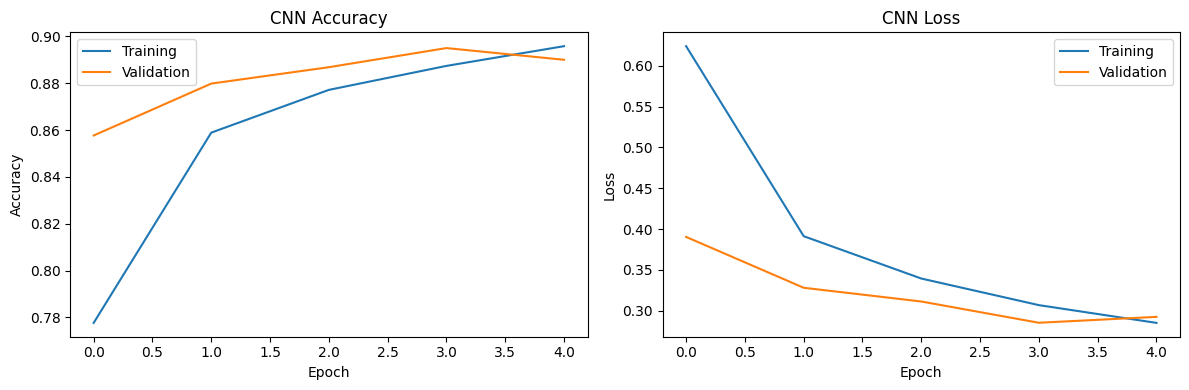

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="Training")
plt.plot(cnn_history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="Training")
plt.plot(cnn_history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Confusion matrix and classification report

              precision    recall  f1-score   support

 T-shirt/top       0.80      0.89      0.84      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.74      0.91      0.81      1000
       Dress       0.89      0.91      0.90      1000
        Coat       0.80      0.82      0.81      1000
      Sandal       0.98      0.97      0.97      1000
       Shirt       0.82      0.49      0.61      1000
     Sneaker       0.93      0.97      0.95      1000
         Bag       0.95      0.98      0.96      1000
  Ankle boot       0.98      0.95      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.88     10000
weighted avg       0.89      0.89      0.88     10000



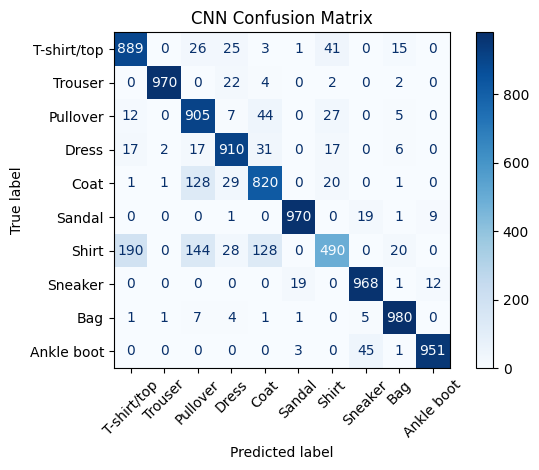

In [ ]:
y_pred_cnn = np.argmax(
    cnn_model.predict(x_test_cnn, verbose=0),
    axis=1
)

print(classification_report(
    y_test,
    y_pred_cnn,
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred_cnn)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(xticks_rotation=45, cmap="Blues")

plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

Predict a sample image

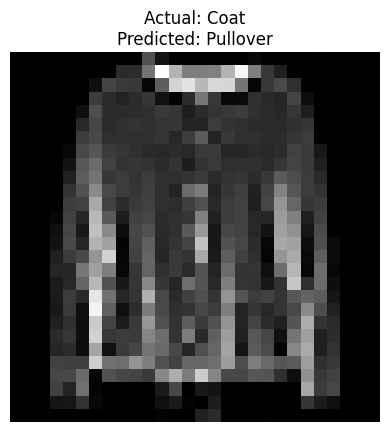

Predicted probabilities: [0.001 0.    0.871 0.    0.066 0.    0.062 0.    0.    0.   ]


In [ ]:
index = 25

image = x_test_cnn[index:index + 1]
prediction = cnn_model.predict(image, verbose=0)[0]
predicted_class = np.argmax(prediction)

plt.imshow(x_test[index], cmap="gray")
plt.title(
    f"Actual: {class_names[y_test[index]]}\n"
    f"Predicted: {class_names[predicted_class]}"
)
plt.axis("off")
plt.show()

print("Predicted probabilities:", prediction.round(3))